In [54]:
import time
import pandas as pd
df = pd.read_csv("client_data.csv")

In [55]:
features = [
    "inquiry_source_score",
    "mentioned_business_income",
    "response_time_hours",
    "requested_pricing_info",
    "lead_hot",
    "years_as_client",
    "filing_complexity_score",
    "addons_purchased",
    "referrals_given",
    "num_income_sources",
    "past_filing_errors",
    "time_spent_selfiling_minutes",
    "deductions_claimed_count",
    "dependents_count",
    "support_contacts_count",
    "acquisition_channel_cost",
    "onboarding_hours",
    "expected_annual_fee"
]

target_column = "premium_upgrade"

In [56]:
data = df[features + [target_column]].copy()
data = data.dropna()

In [57]:
X = data[features].values
y = data[target_column].values.astype(int)

In [58]:
required_columns = features + [target_column]
missing_columns = [col for col in required_columns if col not in df.columns]
print("Missing columns:", missing_columns)

Missing columns: []


In [59]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Training: (1500, 18)
Validation: (500, 18)
Test: (500, 18)


In [60]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

In [61]:
import numpy as np
print("NaN:", np.isnan(X_train_scaled).sum())
print("Infinity:", np.isinf(X_train_scaled).sum())

NaN: 0
Infinity: 0


2D PROJECTION OF THE FEATURES

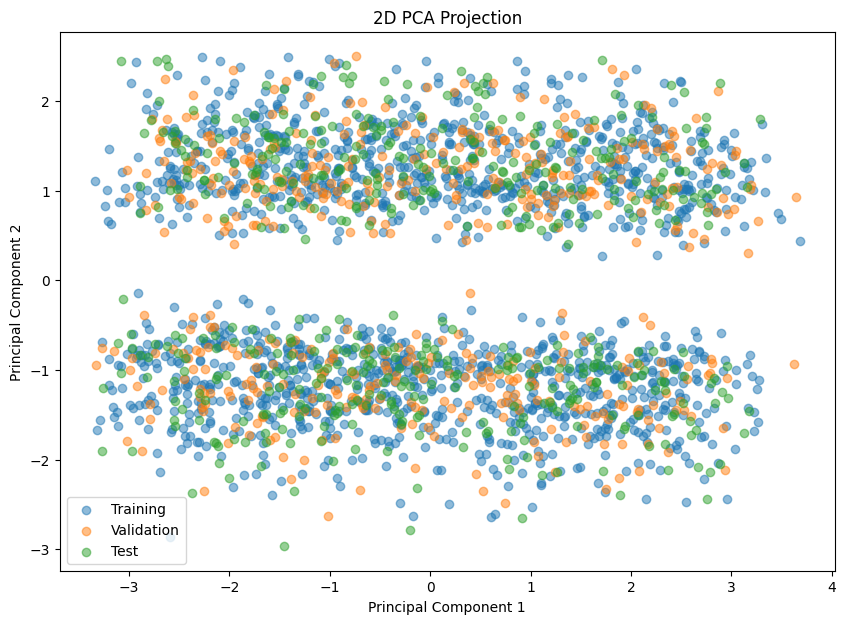

In [62]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)
X_validation_2d = pca.transform(X_validation_scaled)
X_test_2d = pca.transform(X_test_scaled)
plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], label="Training", alpha=0.5)
plt.scatter(X_validation_2d[:, 0], X_validation_2d[:, 1], label="Validation", alpha=0.5)
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], label="Test", alpha=0.5)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection")
plt.legend()
plt.show()

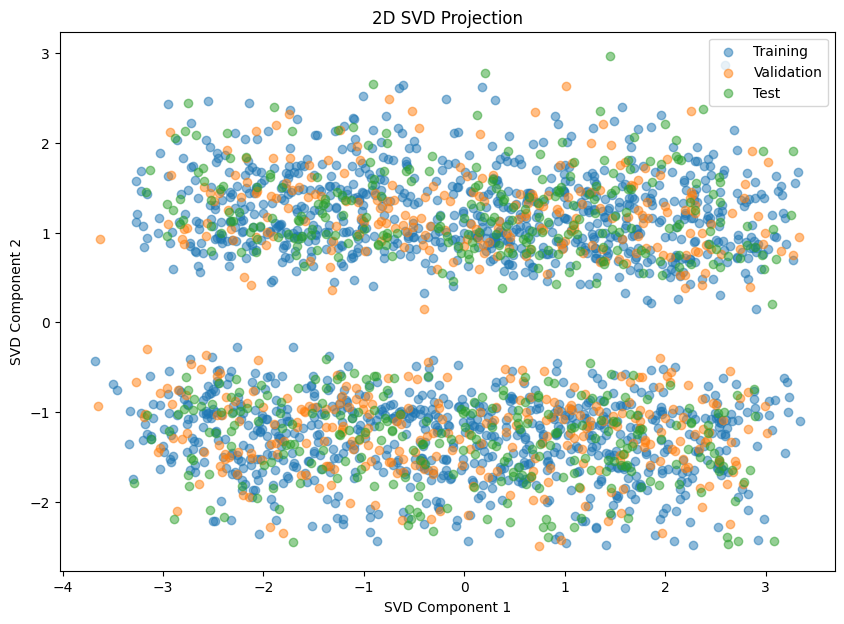

In [63]:
import numpy as np
import matplotlib.pyplot as plt
U_train, S_train, Vt_train = np.linalg.svd(X_train_scaled, full_matrices=False)
X_train_2d = U_train[:, :2] @ np.diag(S_train[:2])
X_validation_2d = X_validation_scaled @ Vt_train[:2].T
X_test_2d = X_test_scaled @ Vt_train[:2].T
plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], label="Training", alpha=0.5)
plt.scatter(X_validation_2d[:, 0], X_validation_2d[:, 1], label="Validation", alpha=0.5)
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], label="Test", alpha=0.5)
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("2D SVD Projection")
plt.legend()
plt.show()

PERCEPTRON IMPLEMENTATION

In [ ]:
def perceptron_train(
    X,
    y,
    learning_rate=0.01,
    epochs=50
):
    weights = np.zeros(X.shape[1])
    bias = 0
    misclassifications = []
    for epoch in range(epochs):
        errors = 0
        for i in range(len(X)):
            linear_output = np.dot(X[i], weights) + bias
            prediction = 1 if linear_output >= 0 else 0
            update = learning_rate * (y[i] - prediction)
            weights = weights + update * X[i]
            bias = bias + update
            if update != 0:
                errors += 1
        misclassifications.append(errors)
    return weights, bias, misclassifications

In [65]:
start_time = time.time()
perceptron_weights, perceptron_bias, misclassifications = perceptron_train(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=50
)
perceptron_training_time = time.time() - start_time
print("Training Time:", perceptron_training_time)

Training Time: 0.5542812347412109


In [66]:
def perceptron_predict(X, weights, bias):
    scores = np.dot(X, weights) + bias
    predictions = (scores >= 0).astype(int)
    return predictions

In [67]:
perceptron_train_predictions = perceptron_predict(
    X_train_scaled,
    perceptron_weights,
    perceptron_bias
)
perceptron_validation_predictions = perceptron_predict(
    X_validation_scaled,
    perceptron_weights,
    perceptron_bias
)
perceptron_test_predictions = perceptron_predict(
    X_test_scaled,
    perceptron_weights,
    perceptron_bias
)

SHOWING HOW DECISION BOUNDARIES AFFECTED DURING TRAINING 

In [68]:
import numpy as np
import matplotlib.pyplot as plt
def perceptron_train_with_boundary(
    X,
    y,
    learning_rate=0.01,
    epochs=10
):
    weights = np.zeros(X.shape[1])
    bias = 0
    boundary_history = []
    for epoch in range(epochs):
        for i in range(len(X)):
            score = np.dot(X[i], weights) + bias
            prediction = 1 if score >= 0 else 0
            error = y[i] - prediction
            if error != 0:
                weights = weights + learning_rate * error * X[i]
                bias = bias + learning_rate * error
        boundary_history.append(
            (weights.copy(), bias)
        )
    return weights, bias, boundary_history

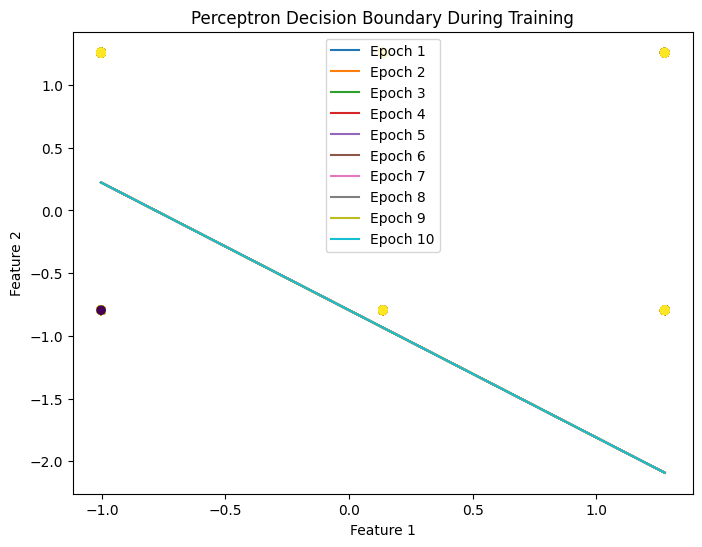

In [69]:
weights, bias, boundary_history = perceptron_train_with_boundary(
    X_train_scaled[:, :2],
    y_train,
    learning_rate=0.01,
    epochs=10
)
plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=y_train
)
x_values = np.linspace(
    X_train_scaled[:, 0].min(),
    X_train_scaled[:, 0].max(),
    100
)
for epoch, (w, b) in enumerate(boundary_history):
    if abs(w[1]) > 1e-10:
        y_values = -(w[0] * x_values + b) / w[1]
        plt.plot(
            x_values,
            y_values,
            label=f"Epoch {epoch + 1}"
        )
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Perceptron Decision Boundary During Training")
plt.legend()
plt.show()

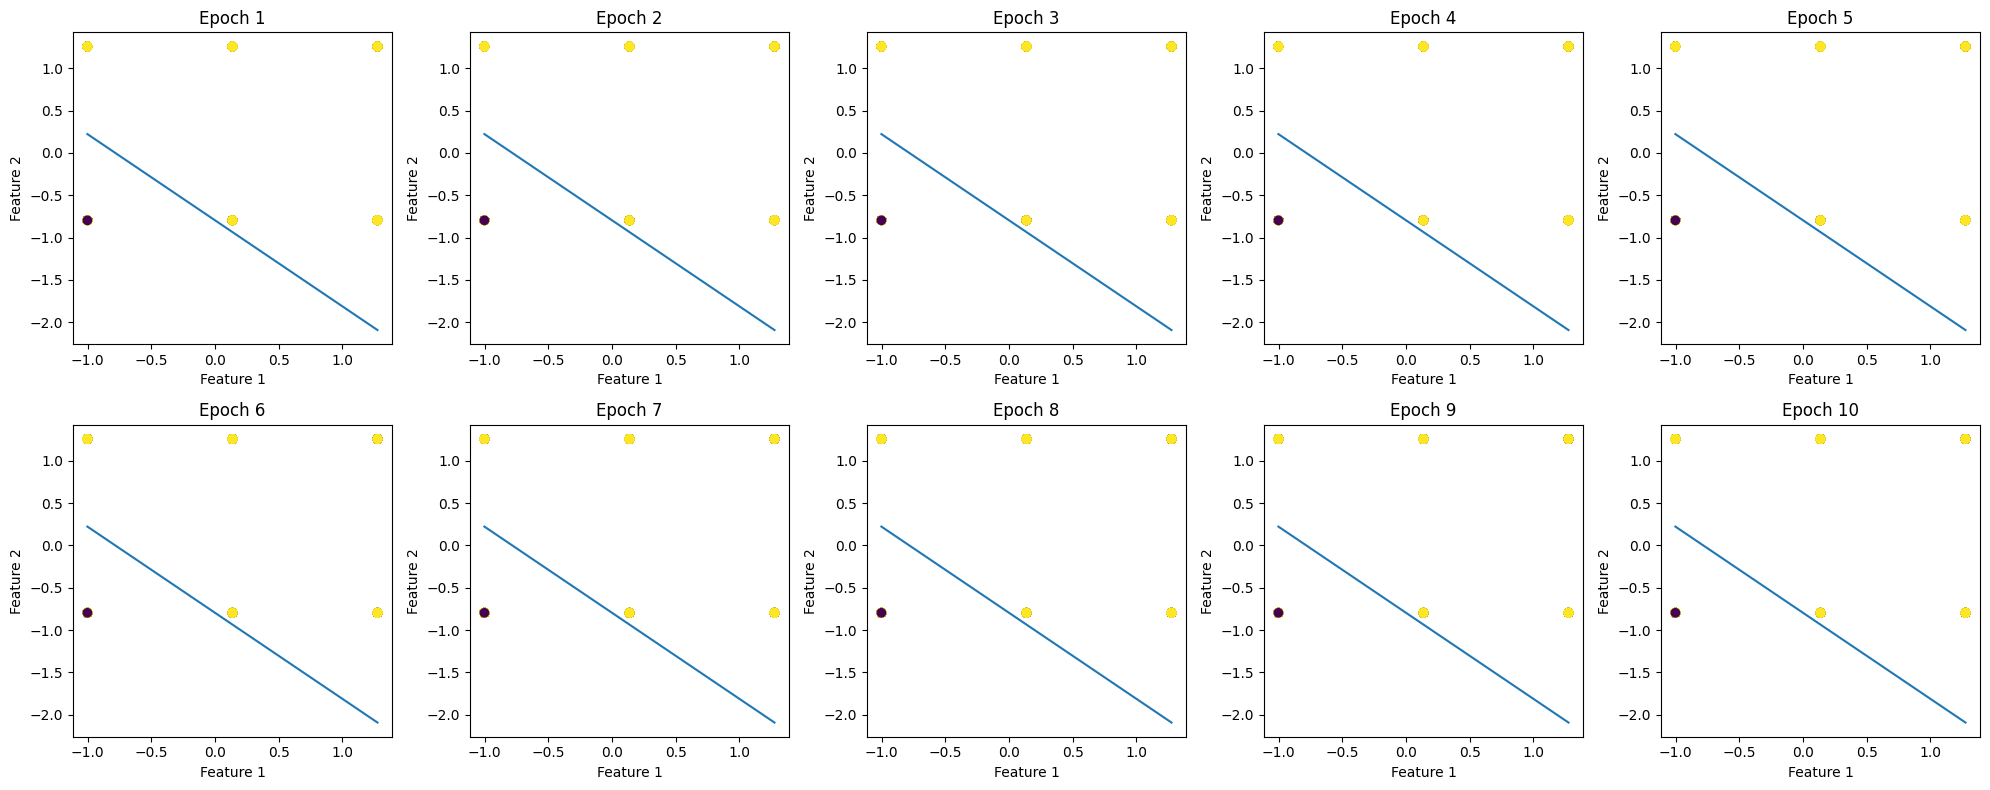

In [70]:
import numpy as np
import matplotlib.pyplot as plt
weights = np.zeros(X_train_scaled[:, :2].shape[1])
bias = 0
boundary_history = []
X = X_train_scaled[:, :2]
for epoch in range(10):
    for i in range(len(X)):
        score = np.dot(X[i], weights) + bias
        prediction = 1 if score >= 0 else 0
        error = y_train[i] - prediction
        if error != 0:
            weights = weights + 0.01 * error * X[i]
            bias = bias + 0.01 * error

    boundary_history.append(
        (weights.copy(), bias)
    )
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
x_values = np.linspace(
    X[:, 0].min(),
    X[:, 0].max(),
    100
)
for epoch, (w, b) in enumerate(boundary_history):
    ax = axes[epoch // 5, epoch % 5]
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y_train
    )
    if abs(w[1]) > 1e-10:
        y_values = -(w[0] * x_values + b) / w[1]
        ax.plot(
            x_values,
            y_values
        )
    ax.set_title(f"Epoch {epoch + 1}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

COUNTING MISSCLASSIFICATION PER EPOCH 

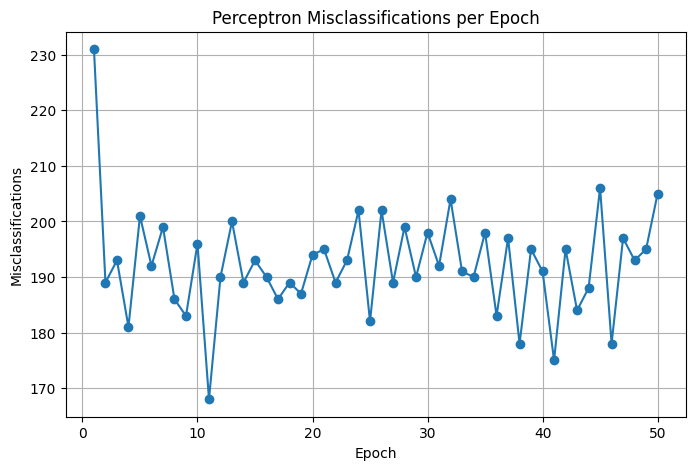

In [71]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(misclassifications) + 1),
    misclassifications,
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Perceptron Misclassifications per Epoch")
plt.grid()
plt.show()

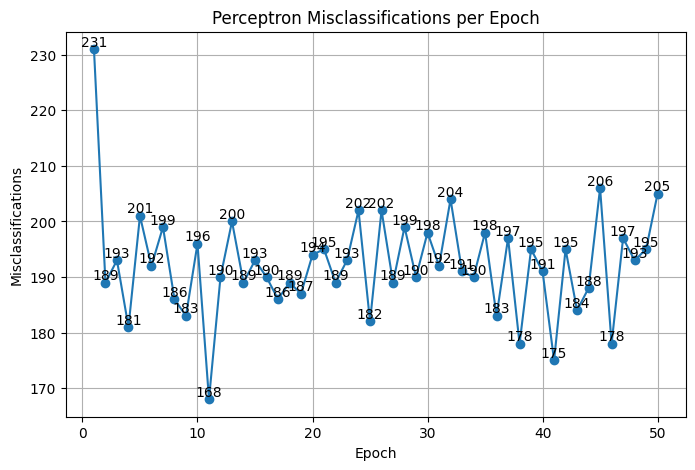

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(misclassifications) + 1),
    misclassifications,
    marker="o"
)
for epoch, count in enumerate(misclassifications, start=1):
    plt.text(
        epoch,
        count,
        str(count),
        ha="center",
        va="bottom"
    )
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Perceptron Misclassifications per Epoch")
plt.grid()
plt.show()

In [73]:
for epoch, count in enumerate(misclassifications, start=1):
    print(f"Epoch {epoch}: {count} misclassifications")

Epoch 1: 231 misclassifications
Epoch 2: 189 misclassifications
Epoch 3: 193 misclassifications
Epoch 4: 181 misclassifications
Epoch 5: 201 misclassifications
Epoch 6: 192 misclassifications
Epoch 7: 199 misclassifications
Epoch 8: 186 misclassifications
Epoch 9: 183 misclassifications
Epoch 10: 196 misclassifications
Epoch 11: 168 misclassifications
Epoch 12: 190 misclassifications
Epoch 13: 200 misclassifications
Epoch 14: 189 misclassifications
Epoch 15: 193 misclassifications
Epoch 16: 190 misclassifications
Epoch 17: 186 misclassifications
Epoch 18: 189 misclassifications
Epoch 19: 187 misclassifications
Epoch 20: 194 misclassifications
Epoch 21: 195 misclassifications
Epoch 22: 189 misclassifications
Epoch 23: 193 misclassifications
Epoch 24: 202 misclassifications
Epoch 25: 182 misclassifications
Epoch 26: 202 misclassifications
Epoch 27: 189 misclassifications
Epoch 28: 199 misclassifications
Epoch 29: 190 misclassifications
Epoch 30: 198 misclassifications
Epoch 31: 192 miscl

In [74]:
plot_features = [
    "filing_complexity_score",
    "support_contacts_count"
]
X_2d = data[plot_features].values
y_2d = data[target_column].values.astype(int)
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

In [75]:
weights_2d, bias_2d, errors_2d = perceptron_train(
    X_2d_scaled,
    y_2d,
    learning_rate=0.01,
    epochs=30
)

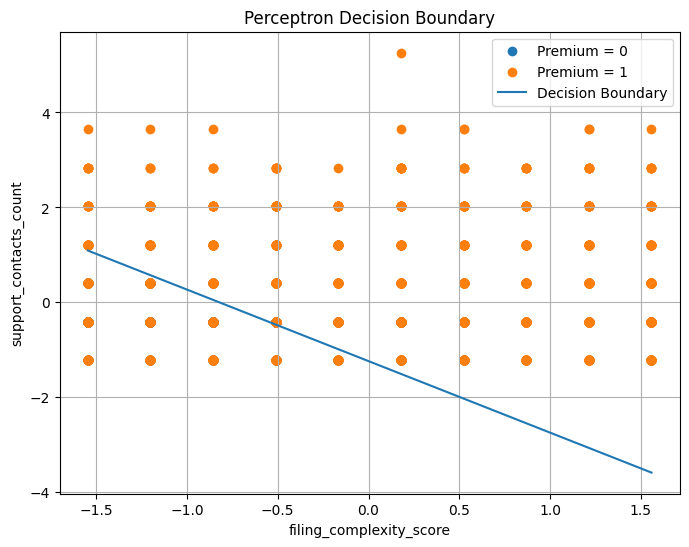

In [76]:
plt.figure(figsize=(8, 6))
for class_value in [0, 1]:
    mask = y_2d == class_value
    plt.scatter(
        X_2d_scaled[mask, 0],
        X_2d_scaled[mask, 1],
        label=f"Premium = {class_value}"
    )
x_values = np.linspace(
    X_2d_scaled[:, 0].min(),
    X_2d_scaled[:, 0].max(),
    100
)
if weights_2d[1] != 0:
    y_values = (
        -(weights_2d[0] * x_values + bias_2d)
        / weights_2d[1]
    )
    plt.plot(
        x_values,
        y_values,
        label="Decision Boundary"
    )
plt.xlabel(plot_features[0])
plt.ylabel(plot_features[1])
plt.title("Perceptron Decision Boundary")
plt.legend()
plt.grid()
plt.show()

IMPLEMENTING SIGMOID FUNCTION LOG LIKELIHOOD GRADIENT DESCENT 

In [77]:
def sigmoid(z):  
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [78]:
def logistic_regression_train(
    X,
    y,
    learning_rate=0.01,
    iterations=5000
):
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0
    cost_history = []
    for i in range(iterations):
        linear_output = np.dot(X, weights) + bias
        probabilities = sigmoid(linear_output)
        errors = probabilities - y
        weight_gradient = (1 / m) * np.dot(
            X.T,
            errors
        )
        bias_gradient = (1 / m) * np.sum(errors)
        weights = weights - learning_rate * weight_gradient
        bias = bias - learning_rate * bias_gradient
        cost = -(
            1 / m
        ) * np.sum(
            y * np.log(probabilities + 1e-15)
            +
            (1 - y) * np.log(1 - probabilities + 1e-15)
        )
        cost_history.append(cost)
    return weights, bias, cost_history

In [79]:
start_time = time.time()
logistic_weights, logistic_bias, logistic_cost_history = (
    logistic_regression_train(
        X_train_scaled,
        y_train,
        learning_rate=0.01,
        iterations=5000
    )
)
logistic_training_time = time.time() - start_time
print("Training Time:", logistic_training_time)

Training Time: 0.5841987133026123


In [80]:
def logistic_predict_probability(
    X,
    weights,
    bias
):
    scores = np.dot(X, weights) + bias
    return sigmoid(scores)

In [81]:
logistic_train_probabilities = logistic_predict_probability(
    X_train_scaled,
    logistic_weights,
    logistic_bias
)
logistic_validation_probabilities = logistic_predict_probability(
    X_validation_scaled,
    logistic_weights,
    logistic_bias
)
logistic_test_probabilities = logistic_predict_probability(
    X_test_scaled,
    logistic_weights,
    logistic_bias
)

In [82]:
def logistic_predict(
    probabilities,
    threshold=0.5
):
    return (probabilities >= threshold).astype(int)

In [83]:
logistic_test_predictions = logistic_predict(
    logistic_test_probabilities,
    threshold=0.5
)

CONVERGENCE SPEED

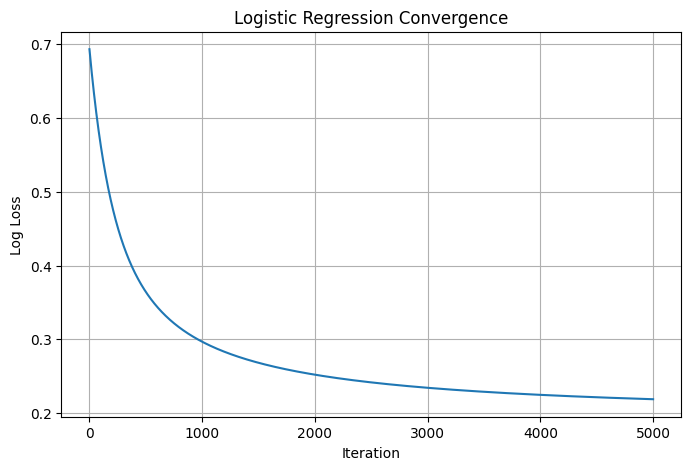

In [84]:
plt.figure(figsize=(8, 5))
plt.plot(
    logistic_cost_history
)
plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Logistic Regression Convergence")
plt.grid()
plt.show()

FINAL ACCURACY COMPARISON 

In [85]:
from sklearn.metrics import accuracy_score
perceptron_accuracy = accuracy_score(
    y_test,
    perceptron_test_predictions
)
logistic_accuracy = accuracy_score(
    y_test,
    logistic_test_predictions
)
print("Perceptron Accuracy:", perceptron_accuracy)
print("Logistic Regression Accuracy:", logistic_accuracy)
print("\nPerceptron Training Time:", perceptron_training_time)
print("Logistic Training Time:", logistic_training_time)

Perceptron Accuracy: 0.826
Logistic Regression Accuracy: 0.892

Perceptron Training Time: 0.5542812347412109
Logistic Training Time: 0.5841987133026123


In [ ]:
X_2d = X_train_scaled[:, :2]
logistic_weights_2d, logistic_bias_2d, logistic_cost_history = logistic_regression_train(
    X_2d,
    y_train,
    learning_rate=0.01,
    iterations=5000
)
perceptron_weights_2d, perceptron_bias_2d, boundary_history = perceptron_train_with_boundary(
    X_2d,
    y_train,
    learning_rate=0.01,
    epochs=10
)

DECISION BOUNDARY DIFFERENCES

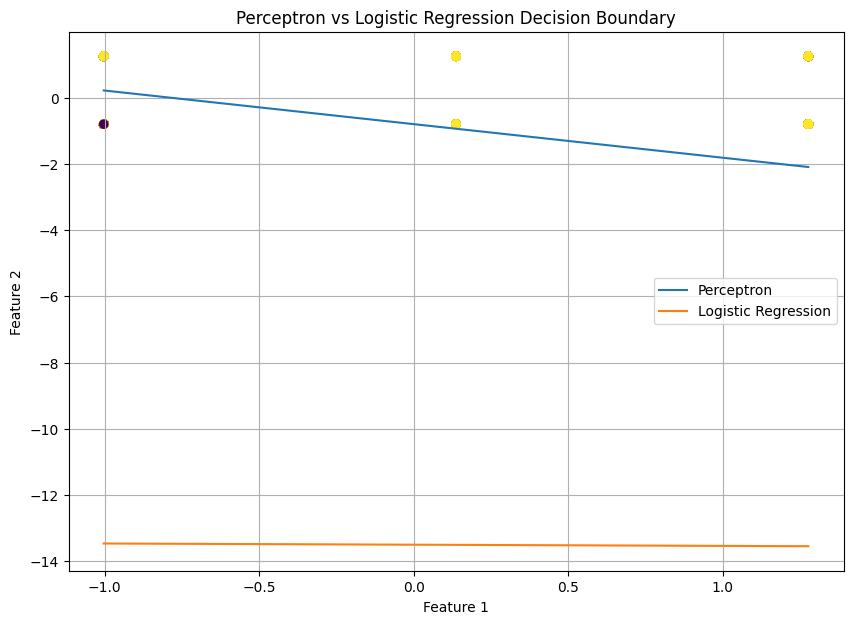

In [87]:
import numpy as np
import matplotlib.pyplot as plt
X = X_train_scaled[:, :2]
plt.figure(figsize=(10, 7))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_train
)
x_values = np.linspace(
    X[:, 0].min(),
    X[:, 0].max(),
    100
)
w_p = weights
b_p = bias
if abs(w_p[1]) > 1e-10:
    y_perceptron = -(w_p[0] * x_values + b_p) / w_p[1]

    plt.plot(
        x_values,
        y_perceptron,
        label="Perceptron"
    )
w_l = logistic_weights_2d
b_l = logistic_bias_2d

if abs(w_l[1]) > 1e-10:
    y_logistic = -(w_l[0] * x_values + b_l) / w_l[1]

    plt.plot(
        x_values,
        y_logistic,
        label="Logistic Regression"
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Perceptron vs Logistic Regression Decision Boundary")
plt.legend()
plt.grid(True)
plt.show()


ACCURACY PRECISION RECALL F1 SCORE AND CONFUSION MATRIX

In [88]:
def confusion_matrix_manual(
    y_true,
    y_pred
):
    tp = np.sum(
        (y_true == 1) & (y_pred == 1)
    )
    tn = np.sum(
        (y_true == 0) & (y_pred == 0)
    )
    fp = np.sum(
        (y_true == 0) & (y_pred == 1)
    )
    fn = np.sum(
        (y_true == 1) & (y_pred == 0)
    )
    return tn, fp, fn, tp

In [89]:
tn, fp, fn, tp = confusion_matrix_manual(
    y_test,
    logistic_test_predictions
)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 30
FP: 38
FN: 16
TP: 416


In [90]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

In [91]:
precision = tp / (tp + fp + 1e-15)

In [92]:
recall = tp / (tp + fn + 1e-15)

In [93]:
f1 = (
    2 * precision * recall
    / (precision + recall + 1e-15)
)

In [94]:
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.892
Precision: 0.9162995594713657
Recall   : 0.9629629629629629
F1-score : 0.9390519187358911


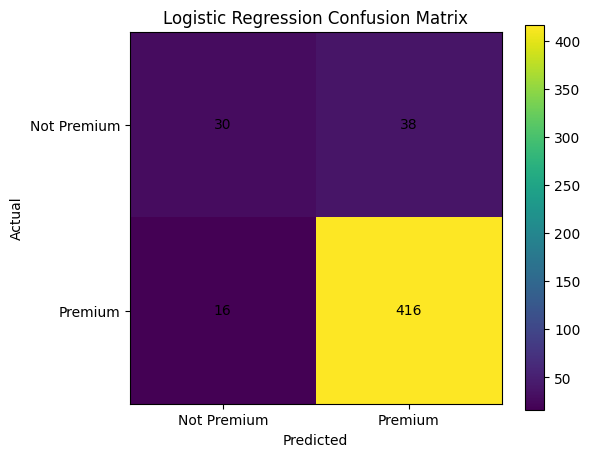

In [95]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Not Premium", "Premium"])
plt.yticks([0, 1], ["Not Premium", "Premium"])
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center"
        )
plt.colorbar()
plt.show()

ROC-AUC CURVE 

ROC-AUC Score: 0.9056712962962964


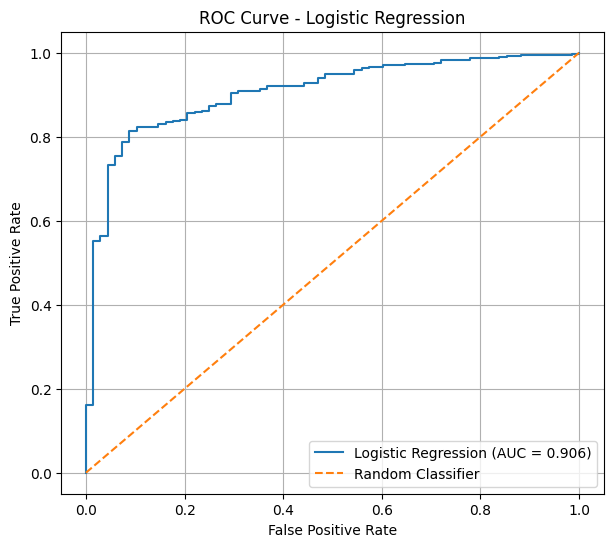

In [96]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(
    y_test,
    logistic_test_probabilities
)
auc_score = roc_auc_score(
    y_test,
    logistic_test_probabilities
)
print("ROC-AUC Score:", auc_score)
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

PRECISION RECALL TRADE - OFF

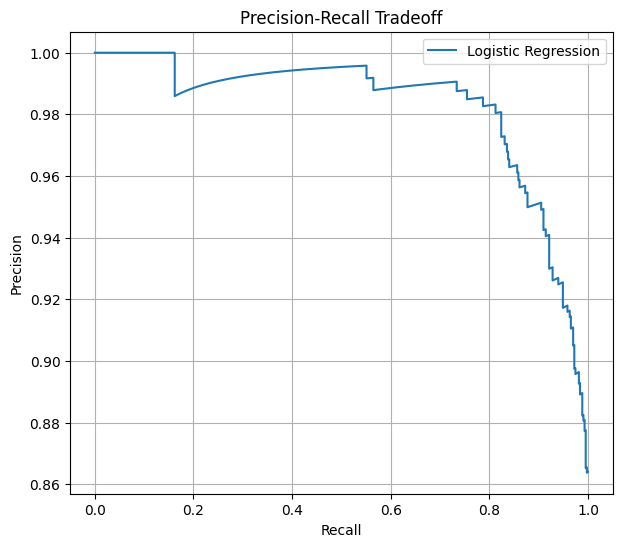

In [97]:
from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(
    y_test,
    logistic_test_probabilities
)
plt.figure(figsize=(7, 6))
plt.plot(
    recall,
    precision,
    label="Logistic Regression"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Tradeoff")
plt.legend()
plt.grid()
plt.show()

VARYING CLASSIFICATION THRESHOLD  

CHOOSING OPTIMAL THRESHOLD 

In [98]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
thresholds = [0.3, 0.5, 0.7]

results = []

for threshold in thresholds:

    predictions = logistic_predict(
        logistic_validation_probabilities,
        threshold=threshold
    )

    accuracy = accuracy_score(y_validation, predictions)
    precision = precision_score(y_validation, predictions)
    recall = recall_score(y_validation, predictions)
    f1 = f1_score(y_validation, predictions)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })
best_result = max(
    results,
    key=lambda x: x["f1_score"]
)
optimal_threshold = best_result["threshold"]
print("\nThreshold Analysis")
for result in results:
    print(
        f"Threshold: {result['threshold']} "
        f"| Accuracy: {result['accuracy']:.4f} "
        f"| Precision: {result['precision']:.4f} "
        f"| Recall: {result['recall']:.4f} "
        f"| F1: {result['f1_score']:.4f}"
    )

print("\nOptimal Threshold:", optimal_threshold)
print("Best F1 Score:", best_result["f1_score"])


Threshold Analysis
Threshold: 0.3 | Accuracy: 0.8820 | Precision: 0.8861 | Recall: 0.9907 | F1: 0.9355
Threshold: 0.5 | Accuracy: 0.8920 | Precision: 0.9238 | Recall: 0.9537 | F1: 0.9385
Threshold: 0.7 | Accuracy: 0.8560 | Precision: 0.9688 | Recall: 0.8611 | F1: 0.9118

Optimal Threshold: 0.5
Best F1 Score: 0.9384965831435079


PRECISION - RECALL TRADEOFF

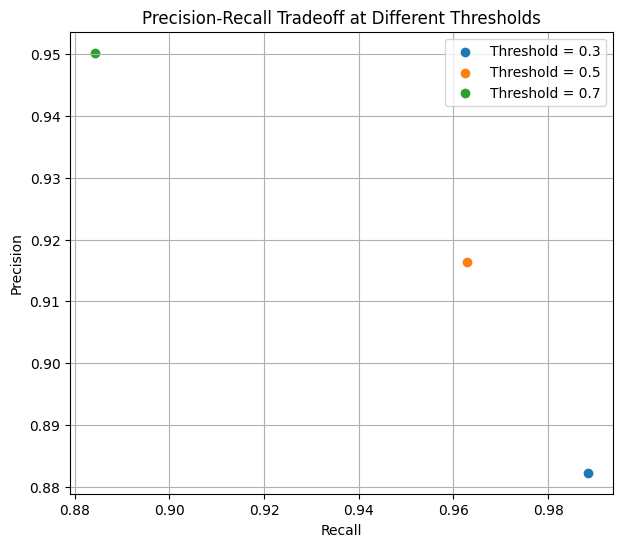

In [99]:
threshold_values = [0.3, 0.5, 0.7]
plt.figure(figsize=(7, 6))
for threshold in threshold_values:
    predictions = logistic_predict(
        logistic_test_probabilities,
        threshold=threshold
    )
    precision_value = np.sum(
        (predictions == 1) & (y_test == 1)
    ) / max(np.sum(predictions == 1), 1)
    recall_value = np.sum(
        (predictions == 1) & (y_test == 1)
    ) / max(np.sum(y_test == 1), 1)
    plt.scatter(
        recall_value,
        precision_value,
        label=f"Threshold = {threshold}"
    )
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Tradeoff at Different Thresholds")
plt.legend()
plt.grid()
plt.show()

In [100]:
X_mean_logistic = X_train.mean(axis=0)
X_std_logistic = X_train.std(axis=0)
X_std_logistic[X_std_logistic == 0] = 1
X_train_scaled = (
    X_train - X_mean_logistic
) / X_std_logistic
X_validation_scaled = (
    X_validation - X_mean_logistic
) / X_std_logistic
X_test_scaled = (
    X_test - X_mean_logistic
) / X_std_logistic

In [101]:
perceptron_weights, perceptron_bias, misclassifications = perceptron_train(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=50
)

In [102]:
np.savez(
    "perceptron_model.npz",
    weights=perceptron_weights,
    bias=perceptron_bias
)

print("Perceptron model saved successfully")

Perceptron model saved successfully


In [ ]:
print("Weights shape:", perceptron_weights.shape)
print("Number of weights:", len(perceptron_weights))
print("Bias:", perceptron_bias)

Weights shape: (18,)
Number of weights: 18
Bias: -0.26000000000000006


In [105]:
import numpy as np

logistic = np.load("logistic_model.npz")

print("Logistic Regression Model")
print("-------------------------")

print("Weights shape:", logistic["weights"].shape)
print("Mean shape:", logistic["mean"].shape)
print("Std shape:", logistic["std"].shape)

print("\nWeights:")
print(logistic["weights"])

print("\nMean:")
print(logistic["mean"])

print("\nStd:")
print(logistic["std"])

Logistic Regression Model
-------------------------
Weights shape: (18,)
Mean shape: (18,)
Std shape: (18,)

Weights:
[-0.03258797  0.13710261  0.05558125  0.10664731  0.00354487 -0.09043772
  1.08286215 -0.07938028 -0.05152757  0.68210559  0.71216473  0.71155569
  1.01924797  0.09653501  0.57946098  0.05972538 -0.0281403   0.0601397 ]

Mean:
[8.80000000e-01 3.87333333e-01 5.94826667e+00 4.94666667e-01
 4.84000000e-01 5.07580000e+00 5.56533333e+00 1.28800000e+00
 7.63333333e-01 3.01066667e+00 9.02666667e-01 4.69520000e+01
 5.46666667e+00 2.07533333e+00 1.49400000e+00 3.39287022e+03
 4.87033333e+00 5.40860848e+03]

Std:
[8.77268488e-01 4.87140865e-01 6.05238936e+00 4.99971555e-01
 4.99743934e-01 2.91876361e+00 2.89397044e+00 1.13771232e+00
 8.65248840e-01 1.42964549e+00 9.35161068e-01 4.67462245e+01
 3.44647969e+00 1.42044297e+00 1.23313854e+00 1.48242573e+03
 2.22022969e+00 1.57731034e+03]
